In [ ]:
# This example notebook uses the AVEHCC dataset (https://huggingface.co/datasets/AdrianNowak/AVEHCC)
# and trains a MobileNet V3 large for the task of vehicle counting on 3.00 second long chunks generated 
# from the audio of location using a single (right sE8) microphone.
#
# The dataset needs to be inside the same folder under the name of "./AVEHCC/". 
# 
# The model has output classes for the number of vehicles per chunk and is trained on a train-validation 
# splits stratified by the number of vehicles per chunk. The count mae is the main metric used for 
# validation. In the end a figure demonstrating the measured performance is shown.
#
# The scripts start with generating the required audio chunks from the available recordings. The chunks
# are then converted to mel-spectrograms with a target resolution of 80x80 pixels. 

In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import random
from pathlib import Path
from time import time
import soundfile as sf
import copy

import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader

from Audio_To_Mel import AudioToMelSpectrogram
from Chunk_Generator import generate_chunks

from MobileNet_V3_large import mobilenet_v3_large

from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, confusion_matrix

In [2]:
# functions for data augmentation

class RandomGaussianNoise:

    '''
        This method applies Gaussian noise to random chunks.

        Parameters:
        
        min_std      minimum standard deviation of the noise
        max_std      maximum standard deviation of the noise
        p            overall probility that noise is applied
        clamp_min    minimum allowed value after adding Gaussian noise.
        clamp_max    maximum allowed value after adding Gaussian noise.
    '''
    
    def __init__(
        self,
        min_std=0.01,
        max_std=0.08,
        p=0.5,
        clamp_min=0.0,
        clamp_max=1.0,
    ):
        self.min_std = min_std
        self.max_std = max_std
        self.p = p
        self.clamp_min = clamp_min
        self.clamp_max = clamp_max

    def __call__(self, x: torch.Tensor) -> torch.Tensor:
        if random.random() >= self.p:
            return x

        std = random.uniform(self.min_std, self.max_std)

        noise = torch.randn_like(x) * std

        x = x + noise

        x = torch.clamp(x, self.clamp_min, self.clamp_max)

        return x

class RandomHorizontalBars:

    '''
        This method masks out random freqeuncies by overlaying horizontal bars
        with an option to prefer lower frequencies.
        
        Parameters:
        
        max_area_percent    maximum area that would be covered
        max_segments        maximum number of horizontal bars
        min_bar_height      minimum height of the horizontal bars
        mask_value          the numerical values of the bars
        lower_bias          a bias to prefer lower frequency areas
        p                   overall probability that a mask is applied
    '''

    def __init__(
        self,
        max_area_percent:float=0.15,
        max_segments:int=3,
        min_bar_height:int=1,
        mask_value:float=0.0,
        lower_bias:int=3.0,
        p:float=0.5,
    ):
        self.max_area_percent = max_area_percent
        self.max_segments = max_segments
        self.min_bar_height = min_bar_height
        self.mask_value = mask_value
        self.lower_bias = lower_bias
        self.p = p

    def __call__(self, mel):
        if random.random() > self.p:
            return mel

        mel = mel.clone()

        n_mels = mel.shape[-2]
        time = mel.shape[-1]

        max_height = max(self.min_bar_height, int(n_mels * self.max_area_percent))

        remaining = int(n_mels * self.max_area_percent)

        for _ in range(self.max_segments):
            if remaining < self.min_bar_height:
                break

            height = random.randint(
                self.min_bar_height,
                min(max_height, remaining)
            )

            r = random.random()
            y0 = int((1.0 - r ** self.lower_bias) * (n_mels - height))
            y1 = y0 + height

            mel[..., y0:y1, :] = self.mask_value

            remaining -= height

        return mel

In [3]:
# most important parameters

num_classes = 4

window_size = 3.0

chunk_folder = "./test_chunks"

model = mobilenet_v3_large(num_classes)

epochs = 20

validation_size = 0.25

microphone = "se"

locations = [1, 2, 3, 4, 5, 6, 7, 8]

# transforms
tf = transforms.Compose([

    RandomGaussianNoise(
        min_std=0.05,
        max_std=0.15,
        p=0.50
    ),

    RandomHorizontalBars(
        max_area_percent=0.20,
        p=0.33,    
        max_segments=1,
        lower_bias=3.0, 
        min_bar_height=2,
        mask_value=0.0,
    )

])

In [4]:
# load the labels from the AVEHCC dataset

t_labels = pd.read_csv("./AVEHCC/labels.csv", sep=";", index_col=0)
t_labels.head(6)

,location,vehicle,timestamp,direction,category,speed,speed_limit
0,1,1,2.168833,left,car,66.2041,50
1,1,2,7.440767,left,car,60.0204,50
2,1,3,12.545867,right,car,83.4048,50
3,1,4,35.435400,left,car,61.1117,50
4,1,5,37.971267,left,car,67.2954,50
5,1,6,39.406033,left,car,70.2054,50


In [5]:
# create chunks

if not os.path.exists(chunk_folder):
    for loc in range(1, 9):
        generate_chunks(t_labels, 
            location        = loc, 
            microphone      = microphone,
            output_folder   = chunk_folder, 
            window_size     = window_size,
            stereo_handling = "right")
        
else:
    print("Chunk output folder already exists.")

create chunks .... | loc:   1 | mic: se   | window_size:  3.0 | offset:  0.0
add more chunks .. | loc:   2 | mic: se   | window_size:  3.0 | offset:  0.0
add more chunks .. | loc:   3 | mic: se   | window_size:  3.0 | offset:  0.0
add more chunks .. | loc:   4 | mic: se   | window_size:  3.0 | offset:  0.0
add more chunks .. | loc:   5 | mic: se   | window_size:  3.0 | offset:  0.0
add more chunks .. | loc:   6 | mic: se   | window_size:  3.0 | offset:  0.0
add more chunks .. | loc:   7 | mic: se   | window_size:  3.0 | offset:  0.0
add more chunks .. | loc:   8 | mic: se   | window_size:  3.0 | offset:  0.0


In [6]:
# load the table with the chunk labels

c_labels = pd.read_csv(chunk_folder + "/chunk_labels.csv", sep=";", index_col=0)
c_labels.head(6)

,chunk_index,location,mic,start_t,end_t,num_events,direction,category
0,0,1,se,0.0,3.0,1,left,car
1,1,1,se,3.0,6.0,0,NaN,NaN
2,2,1,se,6.0,9.0,1,left,car
3,3,1,se,9.0,12.0,0,NaN,NaN
4,4,1,se,12.0,15.0,1,right,car
5,5,1,se,15.0,18.0,0,NaN,NaN


In [7]:
# show the distribution of chunks

print("\nnumber of samples per class:")
print(c_labels.num_events.value_counts())

print("\ntotal number of chunks:", len(c_labels))


number of samples per class:
num_events
0    2071
1     517
2      85
3      11
Name: count, dtype: int64

total number of chunks: 2684


In [8]:
# determine the total number of vehicles and the inherent counting error

# the inherent counting error occurs when the chunks contain classes
# that cannot be predicted by the model. 
# Example: 3-class model -> [no vehicle, one vehicle, two vehicles]
# If the data now contains a three-vehicle chunk the model cant classify 
# it correctly. In the best case scenario it predicts two-vehicles as this
# is the most similar class. This leads to an vehicle undercount of one
# vehicle.
# Hence the inherent error is the counting error that would still occur
# under the assumptinos of perfect classification.

chunks = dict(c_labels.num_events.value_counts())
total_vehicles = 0
countable_vehicles = 0

for key, value in chunks.items():
    total_vehicles += key*value
    countable_vehicles += key*value if key <= (num_classes-1) else (num_classes-1)*value

inherent_error = - (total_vehicles - countable_vehicles)/total_vehicles

print(f"total vehicles     : {total_vehicles}")
print(f"countable vehicles : {countable_vehicles}")
print(f"inherent error     : {round(inherent_error, 3)}")

total vehicles     : 720
countable vehicles : 720
inherent error     : 0.0


In [9]:
# if theres a class with only one sample it will be removed

highest_vehicle_count = c_labels.num_events.value_counts().index.max()

for n in range(highest_vehicle_count+1):
    if len(c_labels[c_labels.num_events == n]) == 1:
        print(f"only one sample for class {n}-vehicle(s) -> REMOVED")
        c_labels = c_labels[c_labels.num_events != n]

In [10]:
# convert the generated audio chunks into mel-spectrograms

# the mel-spectrograms are saved as tensors in the chunk folder. This 
# way the spectrograms dont have to be generated during training.

audio_to_mel = AudioToMelSpectrogram(
    samplerate=48000,
    duration=window_size,
    output_size=(80, 80),
)

# convert chunks into mel spec tensors
def load_audio_chunk(idx):
    folder = chunk_folder
    filename = str(idx) + ".wav"
    path = Path(folder) / filename
    audio, _ = sf.read(path)
    return audio

created_mel_specs = 0
already_existing  = 0

for chunk_index in c_labels.chunk_index:
    
    out_file = Path(chunk_folder) / f"{chunk_index}.pt"
    if out_file.exists():
        already_existing += 1
        continue

    audio = load_audio_chunk(chunk_index)
    mel = audio_to_mel(audio)
    torch.save(mel, out_file)
    created_mel_specs += 1

    if created_mel_specs % 500 == 0:
        print(f"created {created_mel_specs} mel specs ..")

print("created new mel spces     :", created_mel_specs)
print("mel specs already existed :", already_existing)

created 500 mel specs ..
created 1000 mel specs ..
created 1500 mel specs ..
created 2000 mel specs ..
created 2500 mel specs ..
created new mel spces     : 2684
mel specs already existed : 0


In [11]:
# Dataset class for the mel-spectrograms

class MelDataset(Dataset):
    def __init__(self, df:pd.DataFrame, num_classes:int, tf=None):
   
        self.df = df.copy()

        #transforms
        self.tf = tf                
        self.num_classes = num_classes

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        # convert index to chunk index
        chunk_index = self.df["chunk_index"].iloc[idx]

        # load the mel spectrogram
        file = Path(chunk_folder) / f"{chunk_index}.pt"
        mel = torch.load(file, weights_only=True)

        if self.tf:
            mel = self.tf(mel)

        # label (to match the model classes the number of vehicles per
        # chunk is capped but is retained in c_labels.num_events)
        num_events = self.df["num_events"].iloc[idx]
        num_events_capped = min(num_events, self.num_classes - 1)
        label = torch.tensor(
            num_events_capped,
            dtype=torch.long
        )

        return mel, label, chunk_index

def get_train_and_val_loaders(df_train:pd.DataFrame, df_val:pd.DataFrame, num_classes:int, tf:list):

    train_data = MelDataset(df=df_train, num_classes=num_classes, tf=tf)
    val_data = MelDataset(df=df_val, num_classes=num_classes, tf=None)
    
    train_loader = DataLoader(train_data, batch_size=32, num_workers=4, pin_memory=True, persistent_workers=True, shuffle=True)
    val_loader = DataLoader(val_data, batch_size=32, num_workers=4, pin_memory=True, persistent_workers=True, shuffle=False)

    return train_loader, val_loader
    
def get_class_counts(df:pd.DataFrame, num_classes) -> list:
    counts = []
    
    for i in range(num_classes - 1):
        counts.append(len(c_labels[c_labels.num_events == i]))
        
    counts.append(len(c_labels[c_labels.num_events >= (num_classes-1)]))
    return counts

In [12]:
def train_model(model, df_train, df_val, counts, device, tf, epochs, lr, verbose=True):
    
    best_count_mae = 1e10
    best_model_state = None

    best_bias = None
    best_bias_error = None

    all_preds_best_model = None
    all_labels_best_model = None
    true_labels_best_model = None

    # ---------------------------------------------------------
    # Weighted Cross Entropy Loss
    # ---------------------------------------------------------

    counts = torch.tensor(counts, dtype=torch.float32)

    weights = 1.0 / torch.sqrt(counts)
    weights = weights / weights.mean()
    weights = weights.to(device)

    criterion = nn.CrossEntropyLoss(weight=weights)

    # ---------------------------------------------------------
    # Data Loaders
    # ---------------------------------------------------------
    train_loader, val_loader = get_train_and_val_loaders(
        df_train,
        df_val,
        num_classes=num_classes,
        tf=tf
    )

    # ---------------------------------------------------------
    # AdamW Optimizer
    # ---------------------------------------------------------
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=lr,
        weight_decay=1e-4
    )

    model.to(device)

    # ---------------------------------------------------------
    # History
    # ---------------------------------------------------------
    train_loss_list = np.zeros(epochs)
    val_loss_list = np.zeros(epochs)
    macro_f1_list = np.zeros(epochs)
    count_mae_list = np.zeros(epochs)
    bias_list = np.zeros(epochs)
    count_err_list = np.zeros(epochs)

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=0.5,
        patience=3,
        threshold=1e-4,
        min_lr=1e-6
    )

    # ---------------------------------------------------------
    # Training
    # ---------------------------------------------------------
    start_time = time()

    for epoch in range(epochs):

        
        # TRAINING
        model.train()
        running_loss = 0.0

        for images, labels, _ in train_loader:

            images = images.to(device)
            labels = labels.long().to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        avg_train_loss = running_loss / len(train_loader)
        train_loss_list[epoch] = avg_train_loss

        
        # VALIDATION
        model.eval()

        val_running_loss = 0.0

        all_predictions = []
        all_labels = []
        all_logits = []

        true_labels = np.array(df_val.num_events.to_list())

        with torch.no_grad():

            for images, labels, _ in val_loader:

                images = images.to(device)
                labels = labels.long().to(device)

                outputs = model(images)

                loss = criterion(outputs, labels)
                val_running_loss += loss.item()

                predictions = torch.argmax(outputs, dim=1)

                all_predictions.extend(predictions.cpu().numpy())

                all_labels.extend(labels.cpu().numpy())

                all_logits.append(outputs.cpu().numpy())

        avg_val_loss = val_running_loss / len(val_loader)
        val_loss_list[epoch] = avg_val_loss

        all_predictions = np.array(all_predictions)
        all_labels = np.array(all_labels)
        all_logits = np.concatenate(all_logits, axis=0)

        # =====================================================
        # F1-Scores
        # =====================================================
        macro_f1 = f1_score(
            all_labels,
            all_predictions,
            average="macro",
            zero_division=0
        )

        macro_f1_list[epoch] = macro_f1

        # =====================================================
        # Count MAE, Bias and Relative Counting Error
        # =====================================================
        chunk_errors = all_predictions - true_labels

        count_mae = np.mean(np.abs(chunk_errors))
        count_mae_list[epoch] = count_mae

        bias = np.mean(chunk_errors)
        bias_list[epoch] = bias

        actual_vehicles = true_labels.sum()
        counted_vehicles = all_predictions.sum()

        count_err = (counted_vehicles - actual_vehicles) / actual_vehicles

        count_err_list[epoch] = count_err

        # =====================================================
        # BEST MODEL 
        # =====================================================
        if count_mae < best_count_mae:

            best_count_mae = count_mae

            best_model_state = copy.deepcopy(model.state_dict())

            all_preds_best_model = all_predictions.copy()
            all_labels_best_model = all_labels.copy()
            true_labels_best_model = true_labels.copy()

        # =====================================================
        # SCHEDULER
        # =====================================================
        scheduler.step(count_mae)

        current_lr = optimizer.param_groups[0]["lr"]

        # =====================================================
        # OUTPUT
        # =====================================================
        if verbose and (epoch+1)%5==0:

            time_per_epoch = round((time() - start_time) / (epoch + 1), 2)

            print(
                f"Epoch {(epoch+1):3}/{epochs} | "
                f"Time p. Ep.: {time_per_epoch:6} | "
                f"LR: {current_lr:.6f} | "
                f"T-Loss: {avg_train_loss:.4f} | "
                f"V-Loss: {avg_val_loss:.4f} | "
                f"Count MAE: {count_mae:.4f} | "
                f"Bias: {bias:.4f} | "
                f"Macro F1: {macro_f1:.4f} | "
                f"Count Err: {count_err:.4f}"
            )

    # ---------------------------------------------------------
    # Restore best model
    # ---------------------------------------------------------
    model.load_state_dict(best_model_state)
    model.eval()

    return {
        "train_loss": train_loss_list,
        "val_loss": val_loss_list,
        "macro_f1": macro_f1_list,
        "count_mae": count_mae_list,
        "bias": bias_list,
        "count_err": count_err_list,

        "best_model": model,
        "best_bias": best_bias,
        "best_bias_error": best_bias_error,
        "best_count_mae": best_count_mae,

        "val_loader": val_loader,
        "df_val": df_val,

        "predictions": all_preds_best_model,
        "labels": all_labels_best_model,
        "true_labels": true_labels_best_model
    }

In [13]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

cpu


In [ ]:
# TRAINING

results = {}

# random states for training-validation splits
random_states = [31, 41, 59]
n = len(random_states)

# get the class counts for the weighted CrossEntropyLoss
counts = get_class_counts(df=c_labels, num_classes=num_classes)

for index, random_state in enumerate(random_states):
 
    print(f"\nSTART TRAINING {index+1} OF {n}")
    
    df_train, df_val = train_test_split(c_labels, test_size=validation_size, random_state=random_state, stratify=c_labels["num_events"])
    
    results[index] = train_model(
        model        = model, 
        df_train     = df_train, 
        df_val       = df_val, 
        counts       = counts, 
        device       = device,
        tf           = tf,
        epochs       = epochs, 
        lr           = 0.001)


START TRAINING 1 OF 3


c:\Users\Adrian\AppData\Local\Programs\Python\Python314\Lib\site-packages\torch\utils\data\dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


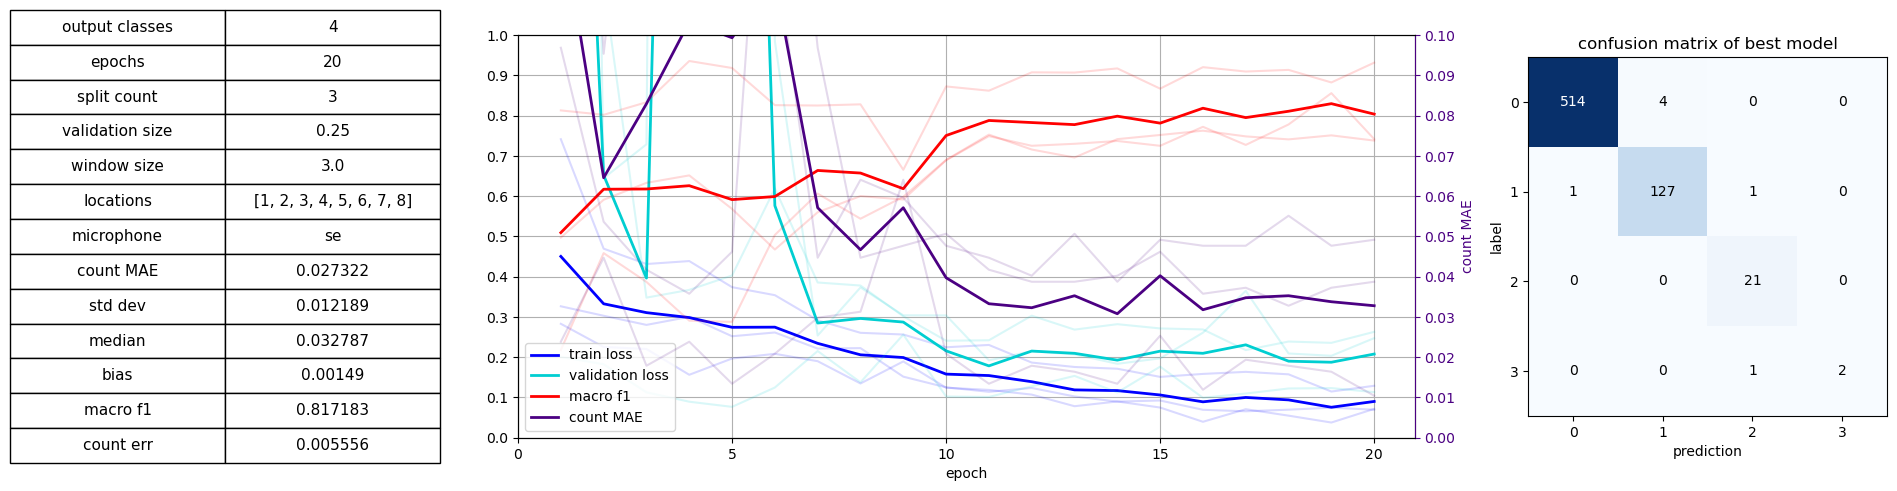

In [ ]:
# plot training statistics

# get the values of the evaluation metrics
best_epochs = np.array([np.argmin(results[i]["count_mae"]) for i in range(n)])
count_mae   = np.array([results[i]["count_mae"][epoch] for i, epoch in enumerate(best_epochs)])
macro_f1    = np.array([results[i]["macro_f1"][epoch] for i, epoch in enumerate(best_epochs)])
bias        = np.array([results[i]["bias"][epoch] for i, epoch in enumerate(best_epochs)])
count_err   = np.array([results[i]["count_err"][epoch] for i, epoch in enumerate(best_epochs)])

# create the figure
fig, axes = plt.subplots(1, 3, figsize=(19, 5), gridspec_kw={"width_ratios": [1, 2.5, 1]})

# ----------------------------------------------------------------------------------
# [LEFT] TABLE
# ----------------------------------------------------------------------------------

# create fields and values
table_data = [
    ["output classes",  num_classes],
    ["epochs",          epochs],
    ["split count",     n],
    ["validation size", validation_size],
    ["window size",     window_size],
    ["locations",       str(locations)],
    ["microphone",      microphone],
    ["count MAE",       count_mae.mean(axis=0).round(6)],
    ["std dev",         count_mae.std(axis=0).round(6)],
    ["median",          np.median(count_mae).round(6)],
    ["bias",            bias.mean(axis=0).round(6)],
    ["macro f1",        macro_f1.mean(axis=0).round(6)],
    ["count err",       count_err.mean(axis=0).round(6)],
]

axes[0].axis("off")

table = axes[0].table(
    cellText=table_data,
    cellLoc="center",
    loc="center"
)

table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1.2, 2)

for cell in table.get_celld().values():
    cell.set_edgecolor("black")

# ----------------------------------------------------------------------------------
# [CENTER] PLOT OF METRICS
# ----------------------------------------------------------------------------------

x = range(1, epochs + 1)

# plot the train loss
train_loss = np.array([results[i]["train_loss"] for i in range(n)])
axes[1].plot(x, train_loss.mean(axis=0), c="blue", label="train loss", linewidth=2)
for i in range(n):
    axes[1].plot(x, train_loss[i], c="blue", alpha=0.15)

# plot the validation loss
val_loss = np.array([results[i]["val_loss"] for i in range(n)])
axes[1].plot(x, val_loss.mean(axis=0), c="darkturquoise", label="validation loss", linewidth=2)
for i in range(n):
    axes[1].plot(x, val_loss[i], c="darkturquoise", alpha=0.15)

# plot the macro f1 score
f1 = np.array([results[i]["macro_f1"] for i in range(n)])
axes[1].plot(x, f1.mean(axis=0), c="red", label="macro f1", linewidth=2)
for i in range(n):
    axes[1].plot(x, f1[i], c="red", alpha=0.15)

# plot the count mae
ax2 = axes[1].twinx()
count_mae_all = np.array([results[i]["count_mae"] for i in range(n)])
ax2.plot(x, count_mae_all.mean(axis=0), c="indigo", alpha=1, label="count MAE", linewidth=2)
for i in range(n):
    ax2.plot(x, count_mae_all[i], c="indigo", alpha=0.15)

axes[1].set_ylim(0, 1)
axes[1].set_xticks(range(0, epochs + 1, 5))
axes[1].set_yticks([i / 10 for i in range(11)])
axes[1].grid()
axes[1].set_xlabel("epoch")

# formatting of secondary y-axis 
ax2.set_ylim(0, 0.1)
ax2.set_yticks([i / 100 for i in range(11)])
ax2.tick_params(axis="y", colors="indigo")
ax2.spines["right"].set_color("indigo")
ax2.set_ylabel("count MAE", color="indigo")

lines1, labels1 = axes[1].get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

axes[1].legend(
    lines1 + lines2,
    labels1 + labels2,
    loc="lower left"
)

# ----------------------------------------------------------------------------------
# [RIGHT] CONFUSION MATRIX OF BEST MODEL
# ----------------------------------------------------------------------------------

best_count_mae = np.argmin(count_mae)
best_model = results[best_count_mae]["best_model"]
val_loader = results[best_count_mae]["val_loader"]

best_model.eval()
    
all_predictions = []
all_labels = []

# get the predictions
with torch.no_grad():
    for images, labels, chunk_indices in val_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = best_model(images)
        predictions = torch.argmax(outputs, dim=1)
        
        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

all_predictions = np.array(all_predictions)
all_labels = np.array(all_labels)

# calculate the confusion matrix
cm = confusion_matrix(all_labels, all_predictions)

im = axes[2].imshow(cm, interpolation="nearest", cmap="Blues")

axes[2].set_title("confusion matrix of best model")
axes[2].set_xlabel("prediction")
axes[2].set_ylabel("label")

axes[2].set_xticks(range(num_classes))
axes[2].set_yticks(range(num_classes))

axes[2].set_xticklabels(range(num_classes))
axes[2].set_yticklabels(range(num_classes))

threshold = cm.max() / 2 if cm.size else 0

for i in range(num_classes):
    for j in range(num_classes):
        axes[2].text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > threshold else "black" )

# ------------------------------------------------------

plt.tight_layout()
plt.show()